<a href="https://colab.research.google.com/github/havaledar/econ3740_f26/blob/main/lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries and data

In [4]:
%%capture

!pip install wooldridge

import statsmodels.formula.api as smf
import wooldridge as woo
import pandas as pd

data = woo.data('wage1')

# Regression

## Simple regression

In [5]:
# Create the model
model0 = smf.ols('wage ~ exper', data)

# Fit the model
results0 = model0.fit()

# Display regression results
print(results0.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     6.766
Date:                Fri, 23 Oct 2026   Prob (F-statistic):            0.00955
Time:                        13:21:02   Log-Likelihood:                -1429.7
No. Observations:                 526   AIC:                             2863.
Df Residuals:                     524   BIC:                             2872.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.3733      0.257     20.908      0.0

## Multiple Linear

In [6]:
# Create the model
model1 = smf.ols('wage ~ exper + tenure', data)

# Fit the model
results1 = model1.fit()

# Display regression results
print(results1.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     37.42
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           6.49e-16
Time:                        13:21:49   Log-Likelihood:                -1397.9
No. Observations:                 526   AIC:                             2802.
Df Residuals:                     523   BIC:                             2815.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.2582      0.243     21.678      0.0

## Log

In [12]:
data['log_exper'] = np.log(data['exper'])

In [14]:
import numpy as np

# Create the model
model2 = smf.ols('wage ~ np.log(exper)', data)
# model2 = smf.ols('wage ~ log_exper', data)

# Fit the model
results2 = model2.fit()

# Display regression results
print(results2.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                  0.044
Method:                 Least Squares   F-statistic:                     25.14
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           7.29e-07
Time:                        13:27:21   Log-Likelihood:                -1420.7
No. Observations:                 526   AIC:                             2845.
Df Residuals:                     524   BIC:                             2854.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.1202      0.388     10.630

## Categorical variables

In [ ]:
# Create the model
model3 = smf.ols('wage ~ C(female)', data)

# Fit the model
results3 = model3.fit()

# Display regression results
print(results3.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.116
Model:                            OLS   Adj. R-squared:                  0.114
Method:                 Least Squares   F-statistic:                     68.54
Date:                Fri, 24 Jan 2025   Prob (F-statistic):           1.04e-15
Time:                        15:23:56   Log-Likelihood:                -1400.7
No. Observations:                 526   AIC:                             2805.
Df Residuals:                     524   BIC:                             2814.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          7.0995      0.210     33.

## Quadratic variables

In [10]:
# Create the model
model4 = smf.ols('wage ~ I(exper**2)', data)
# model4 = smf.ols('wage ~ np.power(exper,2)', data)

# Fit the model
results4 = model4.fit()

# Display regression results
print(results4.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.4795
Date:                Fri, 23 Oct 2026   Prob (F-statistic):              0.489
Time:                        13:24:05   Log-Likelihood:                -1432.8
No. Observations:                 526   AIC:                             2870.
Df Residuals:                     524   BIC:                             2878.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              5.8103      0

## Plot regression line

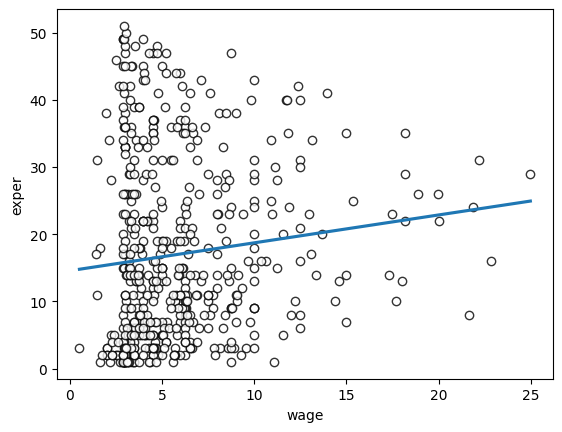

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(x='wage',
            y='exper',
            data=data,
            ci=None,
            scatter_kws={'facecolors':'white',
                         'edgecolors':'black'})

plt.show()

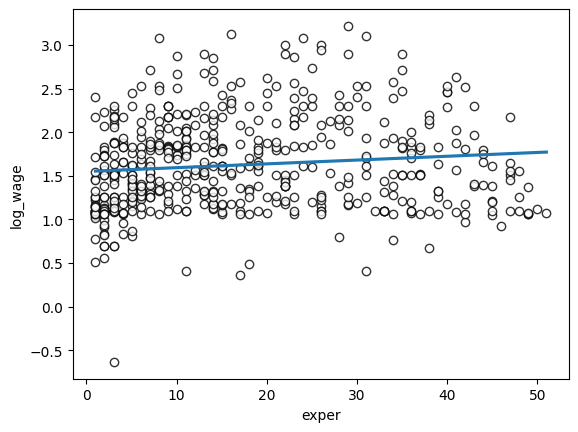

In [16]:
data['log_wage'] = np.log(data['wage'])

sns.regplot(y='log_wage',
            x='exper',
            data=data,
            ci=None,
            scatter_kws={'facecolors':'white',
                         'edgecolors':'black'})

plt.show()

# Correlation matrix

In [19]:
# pd.set_option('display.max_columns', None)
# pd.reset_option("display.max_columns")
# pd.set_option('display.max_rows', None)

data.corr()

,wage,educ,exper,tenure,nonwhite,female,married,numdep,smsa,northcen,south,west,construc,ndurman,trcommpu,trade,services,profserv,profocc,clerocc,servocc,lwage,expersq,tenursq,log_exper,log_wage
wage,1.000000,0.405903,0.112903,0.346890,-0.038520,-0.340098,0.228817,-0.053760,0.177885,-0.029124,-0.102503,0.087732,0.004034,0.073725,0.055940,-0.189848,-0.141624,0.085204,0.441770,-0.140837,-0.253078,0.937062,0.030238,0.267419,0.213983,0.937062
educ,0.405903,1.000000,-0.299542,-0.056173,-0.084654,-0.085029,0.068881,-0.215291,0.224309,0.061372,-0.116625,0.016343,-0.077411,-0.012461,0.107736,-0.059204,-0.072659,0.214198,0.496768,-0.008324,-0.163345,0.431053,-0.331256,-0.069106,-0.206613,0.431053
exper,0.112903,-0.299542,1.000000,0.499291,0.014356,-0.041626,0.316984,-0.056319,-0.117260,0.010588,0.050323,-0.017398,-0.072841,0.101432,-0.048267,-0.104626,0.041499,-0.020599,-0.005615,-0.040385,-0.071080,0.111373,0.960971,0.422942,0.899498,0.111373
tenure,0.346890,-0.056173,0.499291,1.000000,0.011589,-0.197910,0.239889,-0.027037,0.000745,0.014093,-0.025067,-0.021291,-0.025888,0.160519,0.063885,-0.126224,-0.062604,-0.059691,0.090624,-0.072831,-0.112679,0.325538,0.459223,0.921564,0.462623,0.325538
nonwhite,-0.038520,-0.084654,0.014356,0.011589,1.000000,-0.010917,-0.062259,0.077701,-0.014147,-0.080201,0.102098,-0.002287,0.046109,0.036261,-0.072328,-0.048486,0.094866,-0.056680,-0.088552,-0.034138,-0.028769,-0.038888,0.009348,-0.007203,0.031941,-0.038888
female,-0.340098,-0.085029,-0.041626,-0.197910,-0.010917,1.000000,-0.166128,0.033148,0.016545,0.015453,-0.044438,0.054417,-0.082032,-0.092721,-0.018964,-0.053351,0.108833,0.215939,-0.177376,0.355233,0.159226,-0.373677,-0.027860,-0.175623,-0.050721,-0.373677
married,0.228817,0.068881,0.316984,0.239889,-0.062259,-0.166128,1.000000,0.154497,-0.097230,-0.011716,0.075150,-0.022277,0.007452,0.079615,0.038239,-0.136572,-0.054906,0.064603,0.085544,0.025711,-0.157040,0.270669,0.217289,0.166822,0.447403,0.270669
numdep,-0.053760,-0.215291,-0.056319,-0.027037,0.077701,0.033148,0.154497,1.000000,-0.096368,-0.089640,0.087655,0.008480,0.014096,0.016017,-0.014791,0.047992,-0.061708,-0.072145,-0.123401,0.028897,0.055361,-0.095297,-0.130906,-0.056640,0.019449,-0.095297
smsa,0.177885,0.224309,-0.117260,0.000745,-0.014147,0.016545,-0.097230,-0.096368,1.000000,0.055216,-0.231449,0.098553,-0.006885,-0.098107,0.007973,0.017948,0.010028,0.046049,0.145965,0.107216,-0.030039,0.200124,-0.110918,0.004473,-0.121192,0.200124
northcen,-0.029124,0.061372,0.010588,0.014093,-0.080201,0.015453,-0.011716,-0.089640,0.055216,1.000000,-0.429892,-0.261212,-0.021493,-0.000787,-0.059439,0.020417,-0.062645,0.068810,0.068841,-0.024479,0.043253,-0.015858,0.033540,0.009093,-0.028640,-0.015858


# Python

## if

In [20]:

num = -10

if num > 0:
    print("The number is positive.")

In [21]:
num = -10

if num > 0:
    print("The number is positive.")
else:
    print("The number is not positive.")

The number is not positive.


In [22]:
num = 10

if num > 0:
    print("The number is positive.")
elif num == 0:
    print("The number is zero.")
else:
    print("The number is negative.")

The number is positive.


##for

In [ ]:
fruits = ['apple', 'banana', 'cherry']

In [ ]:
fruits[2]

In [ ]:
fruits = ['apple', 'banana', 'cherry']

for f in fruits:
    print(f)

In [23]:
numbers = [1, 2, 3, 4, 5]
total = 0

for num in numbers:
    total += num
    print(total)

# print(total)

1
3
6
10
15


## range

In [24]:
list(range(1, 6))


total = 0

for i in range(1,6):
    total += i

print(f"The total sum is {total}")

The total sum is 15


# Google Drive
No need to upload the files every time you run the code.

Make your submissions **reproducible**.

In [1]:
%%capture

!pip install gdown
import gdown

In [2]:
url = 'https://drive.google.com/file/d/1aPgkXWDv6rd7CcOARjl5U_HAGesmmyTH/view?usp=sharing'
output_filename = 'lfs.dta'
gdown.download(url, output_filename, fuzzy=True ,quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1aPgkXWDv6rd7CcOARjl5U_HAGesmmyTH
To: /content/lfs.dta
100%|██████████| 13.6M/13.6M [00:00<00:00, 86.6MB/s]


'lfs.dta'

In [4]:
import pandas as pd

data = pd.read_stata('lfs.dta', convert_categoricals=False)
data

,REC_NUM,SURVYEAR,SURVMNTH,LFSSTAT,PROV,CMA,AGE_12,AGE_6,SEX,MARSTAT,...,LKATADS,LKANSADS,LKOTHERN,PRIORACT,YNOLOOK,TLOLOOK,SCHOOLN,EFAMTYPE,AGYOWNK,FINALWT
0,1,2023,8,3,46,6,3,6.0,2,6,...,1.0,1.0,1.0,1.0,NaN,NaN,1.0,5,NaN,77
1,2,2023,8,1,10,0,3,6.0,1,2,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2,NaN,66
2,3,2023,8,1,13,0,1,2.0,1,6,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,9,NaN,156
3,4,2023,8,4,24,0,12,NaN,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,NaN,70
4,5,2023,8,4,46,0,12,NaN,1,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103398,103399,2023,8,1,24,1,7,NaN,2,5,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,15,4.0,320
103399,103400,2023,8,3,46,6,6,NaN,1,2,...,1.0,1.0,NaN,3.0,NaN,NaN,1.0,9,1.0,213
103400,103401,2023,8,1,46,0,3,5.0,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,3,1.0,71
103401,103402,2023,8,1,12,0,1,1.0,2,6,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,14,NaN,240


# Stats Canada

In [5]:
%%capture
!pip install stats-can
import stats_can

Total employed, all classes of workers

https://www150.statcan.gc.ca/t1/tbl1/en/cv.action?pid=1410028801

In [6]:
df = stats_can.sc.vectors_to_df('v2066967', periods = 20)

df.columns = ['Total employed']

df

,Total employed
refPer,
2025-02-01,20985.5
2025-03-01,20964.3
2025-04-01,20966.7
2025-05-01,20974.4
2025-06-01,21040.7
2025-07-01,21018.3
2025-08-01,20956.6
2025-09-01,21009.9
2025-10-01,21083.6
